### 1. import library yg dibutuhkan

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import layers
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

### 2. Muat data

#### Data Train

In [2]:
train_ds = image_dataset_from_directory('seg_train/seg_train',image_size = (150,150), batch_size = 32)

Found 14014 files belonging to 6 classes.


#### Data Test

In [3]:
test_ds = image_dataset_from_directory('seg_test/seg_test',image_size = (150,150), batch_size = 32)

Found 2985 files belonging to 6 classes.


### 3. Melihat Nama Kelas Data Train dan test

#### Data train

In [4]:
class_names = train_ds.class_names
print('Nama Kelas :', class_names)

Nama Kelas : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


#### Data test

In [5]:
class_names = test_ds.class_names
print('Nama Kelas :', class_names)

Nama Kelas : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


### 4. Preprocessing

cek piksel

In [6]:
for images, labels in train_ds.take(1):
    print("Nilai minimum piksel:", tf.reduce_min(images).numpy())
    print("Nilai maksimum piksel:", tf.reduce_max(images).numpy())
    break

Nilai minimum piksel: 0.0
Nilai maksimum piksel: 255.0


#### normalisasi piksel

In [7]:
normalization_layer = tf.keras.layers.Rescaling(1./127.5, offset=-1)
train_ds = train_ds.map(lambda x, y:(normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x),y))

### 5. Membangun Model CNN

Transfer Learning

In [8]:
base_model = MobileNetV2(input_shape =(150,150,3), include_top=False, weights='imagenet')

C:\Users\MyBook Hype\AppData\Local\Temp\ipykernel_1352\4074163534.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape =(150,150,3), include_top=False, weights='imagenet')


In [9]:
base_model.trainable = False

In [10]:
model = Sequential([
    RandomFlip('horizontal', input_shape=(150,150,3)),
    RandomRotation(0.1),
    RandomZoom(0.1),

    base_model,

    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(len(class_names), activation='softmax')
])

model.summary()

c:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,619,590 (9.99 MB)

 Trainable params: 361,606 (1.38 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

### 6. Latih model Train

In [12]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(train_ds,validation_data=test_ds,epochs=200,callbacks=[early_stop])

Epoch 1/200


c:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


438/438 ━━━━━━━━━━━━━━━━━━━━ 231s 514ms/step - accuracy: 0.7427 - loss: 0.7092 - val_accuracy: 0.8767 - val_loss: 0.3352
Epoch 2/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 210s 478ms/step - accuracy: 0.8313 - loss: 0.4798 - val_accuracy: 0.8791 - val_loss: 0.3255
Epoch 3/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 198s 451ms/step - accuracy: 0.8505 - loss: 0.4341 - val_accuracy: 0.8637 - val_loss: 0.3447
Epoch 4/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 202s 451ms/step - accuracy: 0.8573 - loss: 0.4134 - val_accuracy: 0.8841 - val_loss: 0.3120
Epoch 5/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 709s 2s/step - accuracy: 0.8576 - loss: 0.4055 - val_accuracy: 0.8898 - val_loss: 0.2946
Epoch 6/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 297s 624ms/step - accuracy: 0.8666 - loss: 0.3880 - val_accuracy: 0.8988 - val_loss: 0.2789
Epoch 7/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 255s 581ms/step - accuracy: 0.8690 - loss: 0.3677 - val_accuracy: 0.8898 - val_loss: 0.2954
Epoch 8/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 297s 679ms/step - accuracy: 0.8687 - loss: 

### 7. Evaluasi Model


#### model train

In [13]:
train_loss, train_accuracy =model.evaluate(train_ds)
print('Train loss :', train_loss)
print('Train Accuracy :',train_accuracy)

438/438 ━━━━━━━━━━━━━━━━━━━━ 194s 442ms/step - accuracy: 0.9052 - loss: 0.2698
Train loss : 0.2698014974594116
Train Accuracy : 0.9051662683486938



##### model test

In [14]:
test_loss , test_accuracy = model.evaluate(test_ds)
print('Test loss :',test_loss)
print('Test Accuracy :', test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 429ms/step - accuracy: 0.8988 - loss: 0.2789
Test loss : 0.27886176109313965
Test Accuracy : 0.8988274931907654


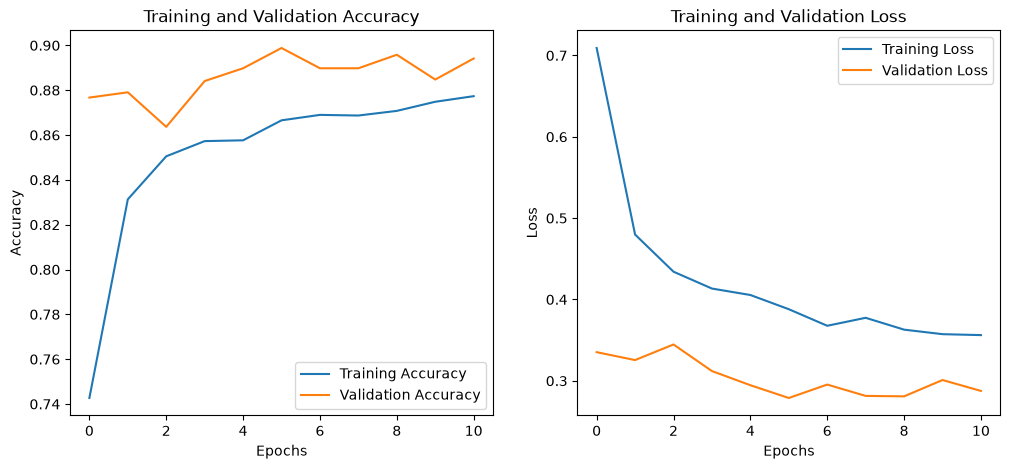

In [15]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))
# 1. Grafik Akurasi (Training vs Validation)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

# 2. Grafik Loss (Training vs Validation)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.savefig('images/learning_curve_MobileNetV2.png', dpi=300, bbox_inches='tight')

plt.show()

### 8. Confusion Matrix

images/Confusion matrix berhasil disimpan sebagai 'confusion_matrix.png'


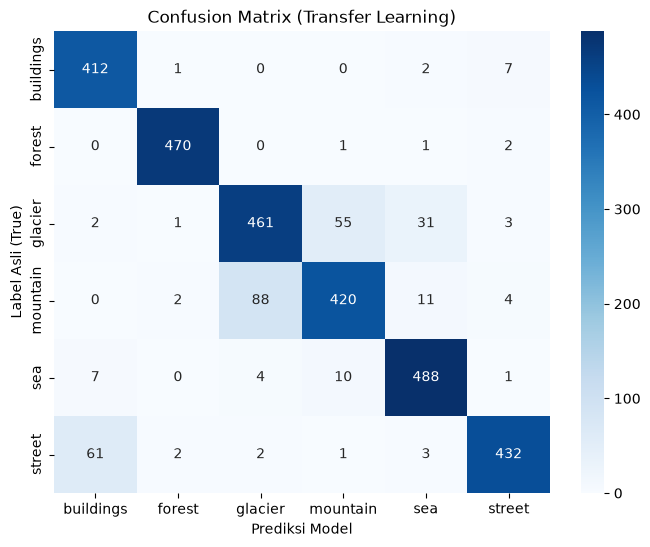


--- Classification Report ---
              precision    recall  f1-score   support

   buildings       0.85      0.98      0.91       422
      forest       0.99      0.99      0.99       474
     glacier       0.83      0.83      0.83       553
    mountain       0.86      0.80      0.83       525
         sea       0.91      0.96      0.93       510
      street       0.96      0.86      0.91       501

    accuracy                           0.90      2985
   macro avg       0.90      0.90      0.90      2985
weighted avg       0.90      0.90      0.90      2985



In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Mengumpulkan semua label asli (true labels) dan hasil prediksi dari test_ds
true_labels = []
predicted_labels = []

for images, labels in test_ds:
    # Prediksi menggunakan model
    preds = model.predict(images, verbose=0)
    pred_classes = np.argmax(preds, axis=1)
    
    # Masukkan ke dalam list
    true_labels.extend(labels.numpy())
    predicted_labels.extend(pred_classes)

# 2. Menghitung Confusion Matrix
cm = confusion_matrix(true_labels, predicted_labels)

# 3. Menampilkan Confusion Matrix dengan Seaborn Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title('Confusion Matrix (Transfer Learning)')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Asli (True)')

# Simpan gambar confusion matrix
plt.savefig('images/confusion_matrix_MobileNetV2.png', dpi=300, bbox_inches='tight')
print("Confusion matrix berhasil disimpan sebagai 'confusion_matrix.png'")

plt.show()

# 4. Menampilkan Laporan Klasifikasi (Precision, Recall, F1-Score per kelas)
print("\n--- Classification Report ---")
print(classification_report(true_labels, predicted_labels, target_names=class_names))